# Day 5 · Demo 2: fit, predict, check

Bayesian statistics for PhD researchers, Aalborg University 2026. This notebook reproduces the figures of the **Day 5 afternoon slides**. Each section names its slide. Run it with the **R (bayes)** kernel from the `demos/` folder; each Stan model compiles the first time it is used (about a minute each).

The data are the same illustrative data as in Demo 1: one person, 30 attempts at targets of 5, 10 and 15 s.

In [1]:
options(tidyverse.quiet = TRUE)
library(tidyverse)   # dplyr for summaries, ggplot2 for figures
library(cmdstanr)    # Stan from R
set.seed(2026)
options(width = 95, repr.plot.width = 8, repr.plot.height = 5, repr.plot.bg = "white")
theme_set(theme_minimal(base_size = 14) + theme(legend.position = "top"))

d <- read_csv("data/slides-one-person.csv", show_col_types = FALSE)   # attempt, target_seconds, recorded_seconds
d <- d |> mutate(x = target_seconds - 10)                              # centred predictor
d |> group_by(target_seconds) |> summarise(attempts = n(), mean = mean(recorded_seconds), sd = sd(recorded_seconds))

This is cmdstanr version 0.9.0



- CmdStanR documentation and vignettes: mc-stan.org/cmdstanr



- CmdStan path: /tmp/claude-0/-home-claude/12b37052-eed4-57b8-ae0f-6457ef895351/scratchpad/env/bin/cmdstan



- CmdStan version: 2.40.0



target_seconds,attempts,mean,sd
<dbl>,<int>,<dbl>,<dbl>
5,10,5.388,0.3302121
10,10,9.731,0.9771324
15,10,14.298,1.3952204


## 1. The fit

*Slide "The fit".* α is her mean recorded time at the 10-s target; β the extra recorded seconds per extra target second; σ the spread around the line.

In [2]:
mod <- cmdstan_model("models/regression.stan")
stan_data <- list(N = nrow(d), x = d$x, y = d$recorded_seconds)
fit <- mod$sample(data = stan_data, chains = 4, seed = 2026, refresh = 0)
fit$summary(c("alpha", "beta", "sigma"), "mean", ~quantile(.x, c(0.05, 0.95)), "rhat", "ess_bulk")
fit$diagnostic_summary()

draws <- fit$draws(format = "df")
c(P_beta_below_1 = mean(draws$beta < 1))

Running MCMC with 4 sequential chains...



Chain 1 Informational Message: The current Metropolis proposal is about to be rejected because of the following issue:



Chain 1 Exception: normal_lpdf: Scale parameter is 0, but must be positive! (in '/tmp/Rtmp4pUYRA/model-7be72409cc2.stan', line 16, column 2 to column 38)



Chain 1 If this warning occurs sporadically, such as for highly constrained variable types like covariance matrices, then the sampler is fine,



Chain 1 but if this warning occurs often then your model may be either severely ill-conditioned or misspecified.



Chain 1 



... (11 outputs left out)

Chain 2 finished in 0.0 seconds.
Chain 3 finished in 0.0 seconds.
Chain 4 finished in 0.0 seconds.

All 4 chains finished successfully.
Mean chain execution time: 0.0 seconds.
Total execution time: 0.6 seconds.



variable,mean,5%,95%,rhat,ess_bulk
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
alpha,9.8120015,9.5062341,10.1196200,1.000881,3219.542
beta,0.8918848,0.8156350,0.9686256,1.001324,3694.111
sigma,1.0279814,0.8234875,1.2869819,1.001465,3328.039


$num_divergent
[1] 0 0 0 0

$num_max_treedepth
[1] 0 0 0 0

$ebfmi
[1] 0.9787126 0.9630070 1.1157239 1.0511664

P_beta_below_1 
         0.988

Each red line is α⁽ˢ⁾ + β⁽ˢ⁾ · x for one posterior draw. On the target scale the intercept is α − 10β.

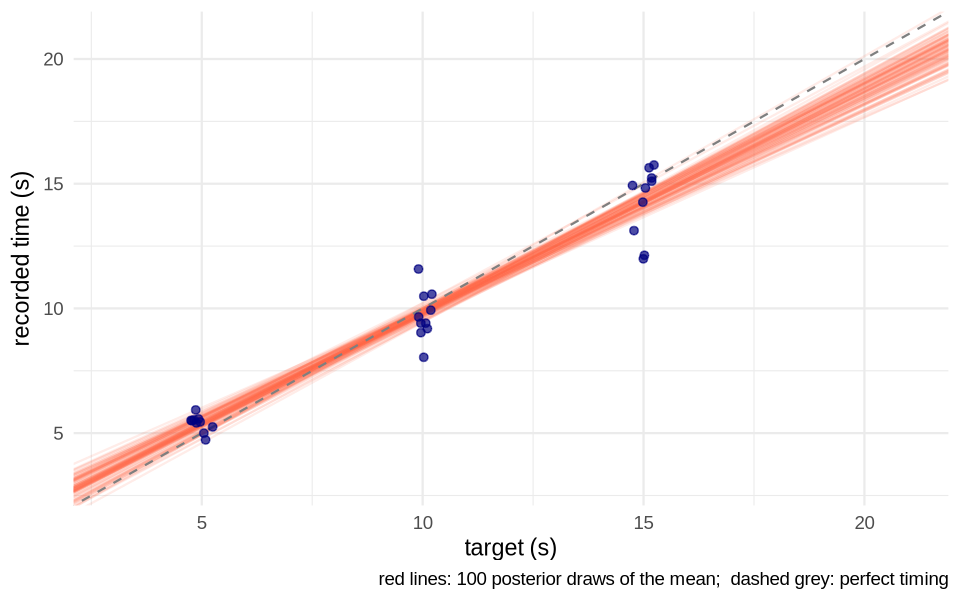

In [3]:
some_draws <- draws |> slice_sample(n = 100)
ggplot() +
  geom_abline(data = some_draws, aes(intercept = alpha - 10 * beta, slope = beta), alpha = 0.12, colour = "tomato") +
  geom_abline(intercept = 0, slope = 1, linetype = "dashed", colour = "grey50") +
  geom_jitter(data = d, aes(x = target_seconds, y = recorded_seconds), width = 0.25, height = 0, colour = "navy", alpha = 0.7) +
  coord_cartesian(xlim = c(3, 21), ylim = c(3, 21)) +
  labs(x = "target (s)", y = "recorded time (s)",
       caption = "red lines: 100 posterior draws of the mean;  dashed grey: perfect timing")

## 2. At 20 s: the mean versus one attempt

*Slide "At 20 s: the mean versus one attempt".* In the Stan program, `mu_20 = alpha + beta * 10` is her **mean** at a 20-s target, and `y_20 ~ Normal(mu_20, sigma)` is **one attempt** there.

quantity,q5,q95,P_below_20
<chr>,<dbl>,<dbl>,<dbl>
mean at 20 s (mu_20),17.90231,19.56556,0.99075
one attempt at 20 s (y_20),16.81483,20.54941,0.87175


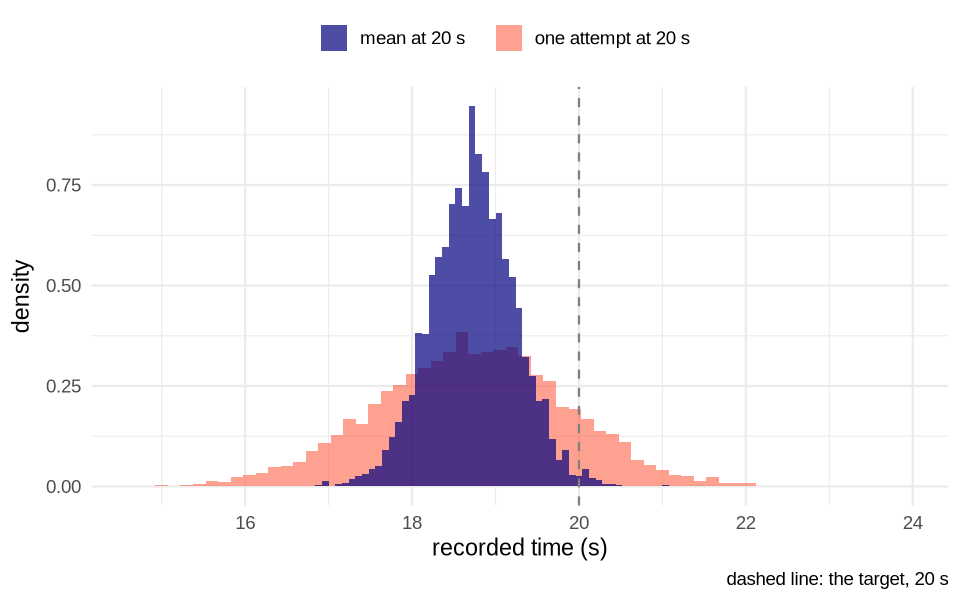

In [4]:
tibble(quantity = c("mean at 20 s (mu_20)", "one attempt at 20 s (y_20)"),
       q5  = c(quantile(draws$mu_20, 0.05), quantile(draws$y_20, 0.05)),
       q95 = c(quantile(draws$mu_20, 0.95), quantile(draws$y_20, 0.95)),
       P_below_20 = c(mean(draws$mu_20 < 20), mean(draws$y_20 < 20)))

ggplot(draws) +
  geom_histogram(aes(x = y_20,  y = after_stat(density), fill = "one attempt at 20 s"), binwidth = 0.15, alpha = 0.6) +
  geom_histogram(aes(x = mu_20, y = after_stat(density), fill = "mean at 20 s"),        binwidth = 0.08, alpha = 0.7) +
  geom_vline(xintercept = 20, linetype = "dashed", colour = "grey50") +
  scale_fill_manual(values = c("mean at 20 s" = "navy", "one attempt at 20 s" = "tomato"), name = NULL) +
  labs(x = "recorded time (s)", y = "density", caption = "dashed line: the target, 20 s")

## 3. Prediction across all targets

*Slide "Prediction across all targets".* For every target on a grid, compute the mean line and one simulated attempt per draw, then take 90% intervals. Beyond 15 s there are no data: the bands rest on the assumption that the line stays straight.

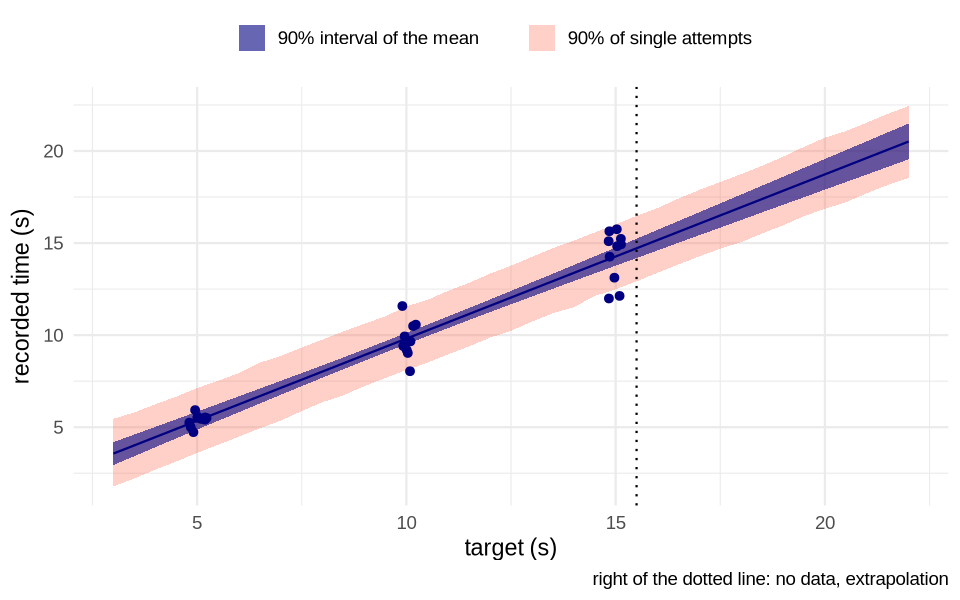

In [5]:
bands <- as_tibble(draws) |>
  select(.draw, alpha, beta, sigma) |>
  cross_join(tibble(target = seq(3, 22, by = 0.5))) |>
  mutate(mean_line = alpha + beta * (target - 10),
         y_sim     = rnorm(n(), mean_line, sigma)) |>
  group_by(target) |>
  summarise(mean = mean(mean_line),
            m_lo = quantile(mean_line, 0.05), m_hi = quantile(mean_line, 0.95),
            y_lo = quantile(y_sim, 0.05),     y_hi = quantile(y_sim, 0.95))

ggplot(bands, aes(x = target)) +
  geom_ribbon(aes(ymin = y_lo, ymax = y_hi, fill = "90% of single attempts"), alpha = 0.3) +
  geom_ribbon(aes(ymin = m_lo, ymax = m_hi, fill = "90% interval of the mean"), alpha = 0.6) +
  geom_line(aes(y = mean), colour = "navy") +
  geom_jitter(data = d, aes(x = target_seconds, y = recorded_seconds), width = 0.25, height = 0, colour = "navy") +
  geom_vline(xintercept = 15.5, linetype = "dotted") +
  scale_fill_manual(values = c("90% interval of the mean" = "navy", "90% of single attempts" = "tomato"), name = NULL) +
  labs(x = "target (s)", y = "recorded time (s)", caption = "right of the dotted line: no data, extrapolation")

## 4. A check: the spread at each target

*Slides "Posterior predictive checks" and "A check: the spread at each target".* If the model were right, would data like hers be typical? The statistic: the SD of the ten attempts at each target. We compute it for many replicated datasets and compare with her data.

In [6]:
# Replicate her 30 attempts once per posterior draw, then take the SD at each target.
# This is what y_rep in the Stan program does; here we draw it in R so that each
# replicated attempt keeps its target in the same row.
# growing = TRUE uses the revised model, where the spread at target t is sigma * t / 10.
replicated_sd <- function(draws, growing = FALSE) {
  as_tibble(draws) |>                  # a plain table of the draws
    select(.draw, alpha, beta, sigma) |>
    cross_join(d |> select(target_seconds, x)) |>
    mutate(spread = if (growing) sigma * target_seconds / 10 else sigma,
           y_rep  = rnorm(n(), alpha + beta * x, spread)) |>
    group_by(.draw, target_seconds) |>
    summarise(rep_sd = sd(y_rep), .groups = "drop")
}
observed_sd <- d |> group_by(target_seconds) |> summarise(obs_sd = sd(recorded_seconds))

ppc_plot <- function(rep) {
  ggplot(rep, aes(x = rep_sd)) +
    geom_histogram(aes(fill = "replicated datasets"), bins = 40, alpha = 0.7) +
    geom_vline(data = observed_sd, aes(xintercept = obs_sd, colour = "observed data"), linewidth = 1.3) +
    facet_wrap(~ target_seconds, labeller = label_both) +
    scale_fill_manual(values = c("replicated datasets" = "grey60"), name = NULL) +
    scale_colour_manual(values = c("observed data" = "tomato"), name = NULL) +
    coord_cartesian(xlim = c(0, 2.6)) +
    labs(x = "SD of the 10 attempts at this target (s)", y = "number of draws")
}
ppc_table <- function(rep) {
  rep |> group_by(target_seconds) |>
    summarise(rep_q5 = quantile(rep_sd, 0.05), rep_q95 = quantile(rep_sd, 0.95)) |>
    left_join(observed_sd, by = "target_seconds")
}

target_seconds,rep_q5,rep_q95,obs_sd
<dbl>,<dbl>,<dbl>,<dbl>
5,0.5799814,1.491608,0.3302121
10,0.5785664,1.501932,0.9771324
15,0.5898411,1.475026,1.3952204


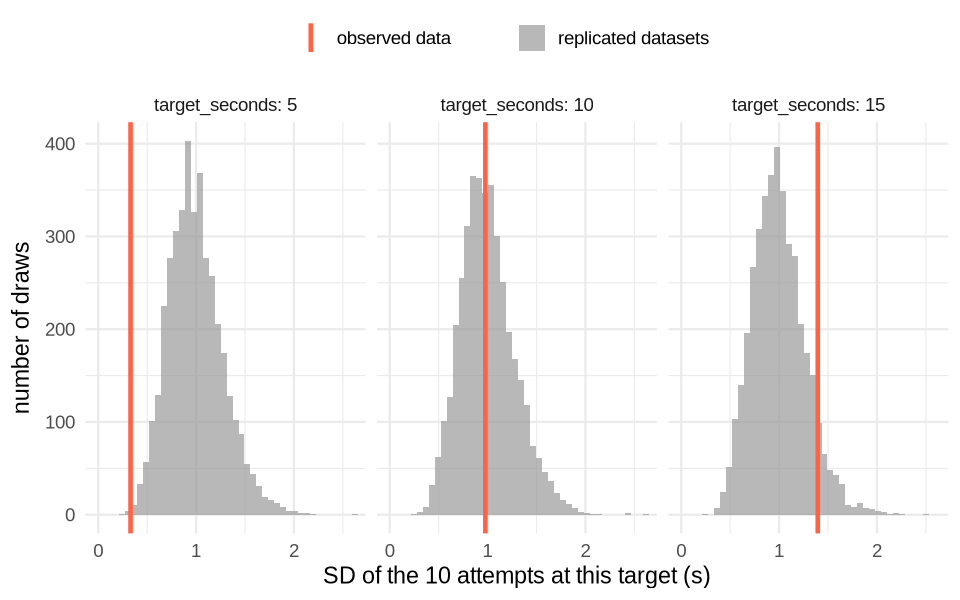

In [7]:
rep_constant <- replicated_sd(draws)
ppc_table(rep_constant)
ppc_plot(rep_constant)

## 5. The residuals show it too

*Slide "The residuals show it too".* Residual = recorded time − fitted mean, using the posterior means of α and β.

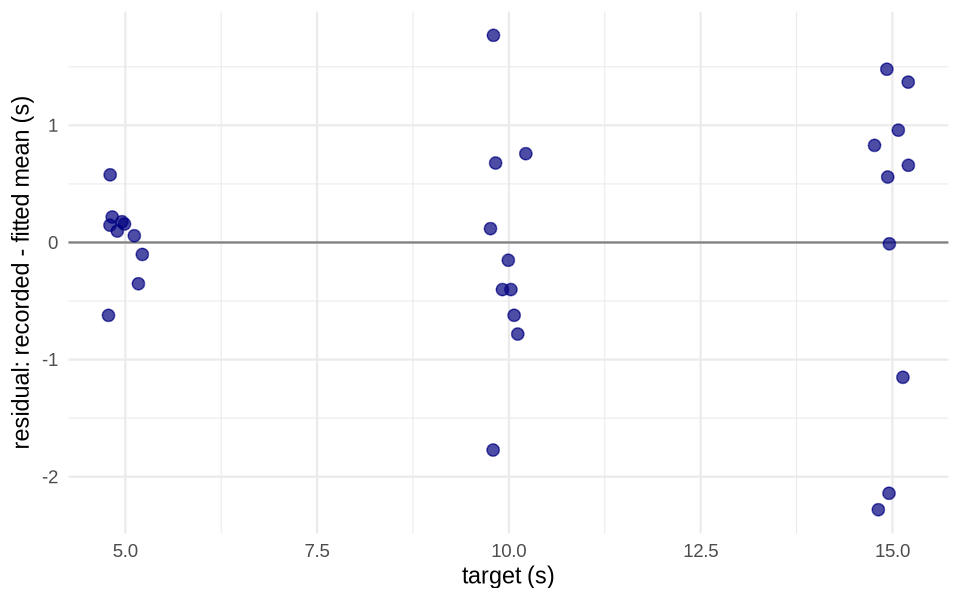

In [8]:
residuals <- d |> mutate(fitted = mean(draws$alpha) + mean(draws$beta) * x,
                         residual = recorded_seconds - fitted)
ggplot(residuals, aes(x = target_seconds, y = residual)) +
  geom_hline(yintercept = 0, colour = "grey50") +
  geom_jitter(width = 0.25, height = 0, size = 3, alpha = 0.7, colour = "navy") +
  labs(x = "target (s)", y = "residual: recorded - fitted mean (s)")

## 6. Revise: the spread grows with the target

*Slide "Revise: the spread grows with the target".* One changed line in the Stan program: the spread at target t is σ · t / 10, so σ is the spread at a 10-s target.

In [9]:
writeLines(readLines("models/regression_growing_sd.stan"))
fit_growing <- cmdstan_model("models/regression_growing_sd.stan")$sample(data = stan_data, chains = 4, seed = 2026, refresh = 0)
fit_growing$diagnostic_summary()
draws_growing <- fit_growing$draws(format = "df")

tibble(model = c("constant spread", "growing spread"),
       beta  = c(mean(draws$beta), mean(draws_growing$beta)),
       y_20_q5  = c(quantile(draws$y_20, 0.05), quantile(draws_growing$y_20, 0.05)),
       y_20_q95 = c(quantile(draws$y_20, 0.95), quantile(draws_growing$y_20, 0.95)))

// Linear regression whose spread grows in proportion to the target
data {
  int<lower=1> N;
  vector[N] x;                 // target - 10 (seconds)
  vector[N] y;                 // recorded time (seconds)
}
parameters {
  real alpha;
  real beta;
  real<lower=0> sigma;         // spread at target 10 s
}
model {
  alpha ~ normal(10, 2);
  beta ~ normal(1, 0.5);
  sigma ~ normal(0, 2);
  y ~ normal(alpha + beta * x, sigma * (x + 10) / 10);   // spread proportional to the target
}
generated quantities {
  real mu_20 = alpha + beta * 10;
  real y_20 = normal_rng(mu_20, sigma * 2);
  array[N] real y_rep = normal_rng(alpha + beta * x, sigma * (x + 10) / 10);
}


Running MCMC with 4 sequential chains...

Chain 1 finished in 0.1 seconds.
Chain 2 finished in 0.1 seconds.
Chain 3 finished in 0.0 seconds.
Chain 4 finished in 0.0 seconds.

All 4 chains finished successfully.
Mean chain execution time: 0.1 seconds.
Total execution time: 0.5 seconds.



$num_divergent
[1] 0 0 0 0

$num_max_treedepth
[1] 0 0 0 0

$ebfmi
[1] 1.004727 1.000940 1.042685 1.025179

model,beta,y_20_q5,y_20_q95
<chr>,<dbl>,<dbl>,<dbl>
constant spread,0.8918848,16.81483,20.54941
growing spread,0.8839886,15.51507,21.80321


The same check for the revised model:

target_seconds,rep_q5,rep_q95,obs_sd
<dbl>,<dbl>,<dbl>,<dbl>
5,0.2547394,0.6513385,0.3302121
10,0.5135617,1.3026248,0.9771324
15,0.7609408,1.9468373,1.3952204


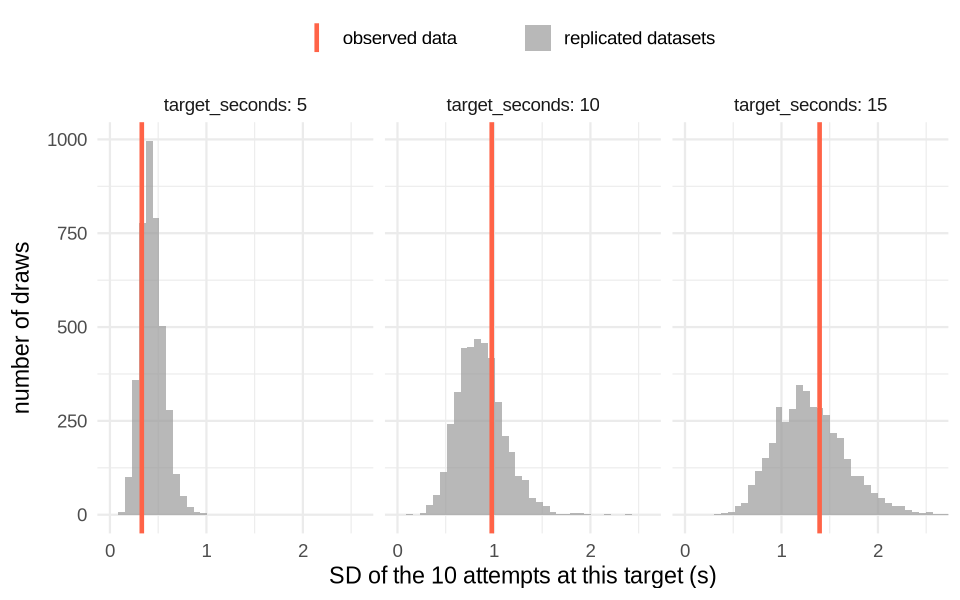

In [10]:
rep_growing <- replicated_sd(draws_growing, growing = TRUE)
ppc_table(rep_growing)
ppc_plot(rep_growing)

## 7. An unusual attempt

*Slides "An unusual attempt" and "Robust regression: Student-t errors".* Suppose one 15-s attempt (attempt 25) was recorded as 24 s: she forgot to click. Fit the normal model and the Student-t model to these data.

In [11]:
d_unusual <- d |> mutate(recorded_seconds = if_else(attempt == 25, 24, recorded_seconds))
data_unusual <- list(N = nrow(d_unusual), x = d_unusual$x, y = d_unusual$recorded_seconds)

fit_normal_unusual <- mod$sample(data = data_unusual, chains = 4, seed = 2026, refresh = 0)
fit_t_unusual <- cmdstan_model("models/regression_t.stan")$sample(data = data_unusual, chains = 4, seed = 2026, refresh = 0)

comparison <- bind_rows(
  fit$summary(c("alpha", "beta", "sigma"), "mean", ~quantile(.x, c(0.05, 0.95))) |> mutate(fit = "normal, original data"),
  fit_normal_unusual$summary(c("alpha", "beta", "sigma"), "mean", ~quantile(.x, c(0.05, 0.95))) |> mutate(fit = "normal, with unusual attempt"),
  fit_t_unusual$summary(c("alpha", "beta", "sigma"), "mean", ~quantile(.x, c(0.05, 0.95))) |> mutate(fit = "Student-t, with unusual attempt"))
comparison |> filter(variable != "alpha")

Running MCMC with 4 sequential chains...



Chain 1 Informational Message: The current Metropolis proposal is about to be rejected because of the following issue:



Chain 1 Exception: normal_lpdf: Scale parameter is 0, but must be positive! (in '/tmp/Rtmp4pUYRA/model-7be72409cc2.stan', line 16, column 2 to column 38)



Chain 1 If this warning occurs sporadically, such as for highly constrained variable types like covariance matrices, then the sampler is fine,



Chain 1 but if this warning occurs often then your model may be either severely ill-conditioned or misspecified.



Chain 1 



... (17 outputs left out)

Chain 4 but if this warning occurs often then your model may be either severely ill-conditioned or misspecified.



Chain 4 



Chain 4 finished in 0.0 seconds.

All 4 chains finished successfully.
Mean chain execution time: 0.0 seconds.
Total execution time: 0.5 seconds.



variable,mean,5%,95%,fit
<chr>,<dbl>,<dbl>,<dbl>,<chr>
beta,0.8918848,0.8156350,0.9686256,"normal, original data"
sigma,1.0279814,0.8234875,1.2869819,"normal, original data"
beta,0.9836953,0.8364133,1.1299656,"normal, with unusual attempt"
sigma,2.0764363,1.6639731,2.5737921,"normal, with unusual attempt"
beta,0.9189216,0.8343453,0.9994888,"Student-t, with unusual attempt"
sigma,0.9184096,0.6642750,1.2337181,"Student-t, with unusual attempt"


The three fitted mean lines (posterior means of α and β).

fit,alpha,beta
<chr>,<dbl>,<dbl>
"Student-t, with unusual attempt",9.908809,0.9189216
"normal, original data",9.812002,0.8918848
"normal, with unusual attempt",10.115182,0.9836953


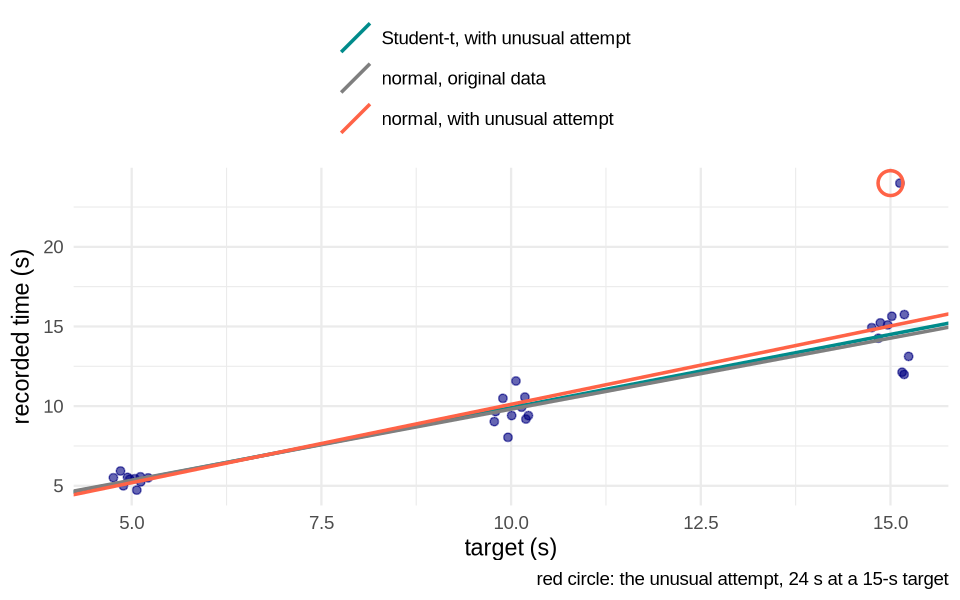

In [12]:
fitted_lines <- comparison |> group_by(fit) |>
  summarise(alpha = mean[variable == "alpha"], beta = mean[variable == "beta"])
fitted_lines

ggplot() +
  geom_jitter(data = d_unusual, aes(x = target_seconds, y = recorded_seconds), width = 0.25, height = 0, colour = "navy", alpha = 0.6) +
  annotate("point", x = 15, y = 24, size = 6, shape = 21, colour = "tomato", stroke = 1.5) +
  geom_abline(data = fitted_lines, aes(intercept = alpha - 10 * beta, slope = beta, colour = fit), linewidth = 1) +
  scale_colour_manual(values = c("normal, original data" = "grey50", "normal, with unusual attempt" = "tomato",
                                 "Student-t, with unusual attempt" = "darkcyan"), name = NULL) +
  guides(colour = guide_legend(ncol = 1)) +
  labs(x = "target (s)", y = "recorded time (s)", caption = "red circle: the unusual attempt, 24 s at a 15-s target")

## 8. Always plot: Anscombe's quartet

*Slide "Always plot: Anscombe's quartet".* R's built-in `anscombe` data: four datasets with the same mean of y, the same fitted slope and the same correlation.

dataset,mean_y,slope,correlation
<chr>,<dbl>,<dbl>,<dbl>
dataset 1,7.500909,0.5000909,0.8164205
dataset 2,7.500909,0.5000000,0.8162365
dataset 3,7.500000,0.4997273,0.8162867
dataset 4,7.500909,0.4999091,0.8165214


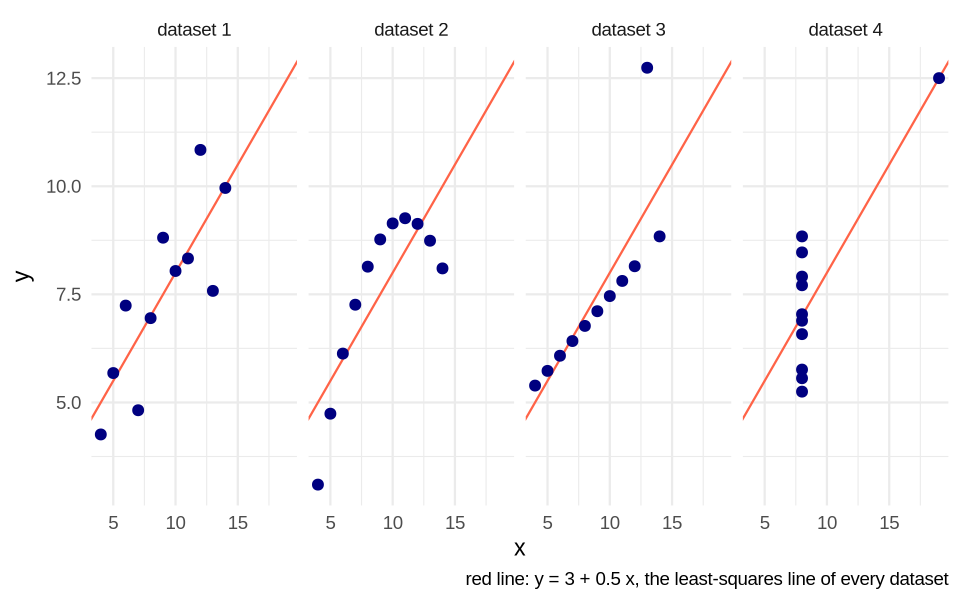

In [13]:
quartet <- bind_rows(tibble(dataset = "dataset 1", x = anscombe$x1, y = anscombe$y1),
                     tibble(dataset = "dataset 2", x = anscombe$x2, y = anscombe$y2),
                     tibble(dataset = "dataset 3", x = anscombe$x3, y = anscombe$y3),
                     tibble(dataset = "dataset 4", x = anscombe$x4, y = anscombe$y4))

quartet |> group_by(dataset) |>
  summarise(mean_y = mean(y), slope = cov(x, y) / var(x), correlation = cor(x, y))

ggplot(quartet, aes(x = x, y = y)) +
  geom_abline(intercept = 3, slope = 0.5, colour = "tomato") +
  geom_point(size = 2.5, colour = "navy") +
  facet_wrap(~ dataset, nrow = 1) +
  labs(caption = "red line: y = 3 + 0.5 x, the least-squares line of every dataset")